# Logistic regression vs SVM: a visual comparison

Learning aid for section C, not part of the hand-in. Run from inside `handin-titanic/visuals/`, after `clean.py`.

The two-feature plots are for seeing how each model draws its boundary. They are **not** results for the report: the real model uses all features.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

SURVIVED, DIED, NEUTRAL = "#2a78d6", "#eb6834", "#f0efec"
INK, MUTED = "#0b0b0b", "#52514e"
PROBABILITY = LinearSegmentedColormap.from_list("probability", [DIED, NEUTRAL, SURVIVED])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

train = pd.read_csv("../data/titanic_800_train.csv")
X = train.drop(columns="Survived")
y = train["Survived"]


def scatter(ax, X2, y2, size=22):
    # Shape as well as colour, so the classes stay apart without relying on colour.
    ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=size, c=SURVIVED, marker="o", edgecolor="#fcfcfb", linewidth=0.5, label="Survived")
    ax.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=size, c=DIED, marker="s", edgecolor="#fcfcfb", linewidth=0.5, label="Died")


def compare(X2, y2, xlabel, ylabel, ylim=None, size=22):
    """Left: logistic regression with its probabilities. Right: linear SVM with its street."""
    log_reg = LogisticRegression().fit(X2, y2)
    svm = SVC(kernel="linear", C=1).fit(X2, y2)
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = ylim if ylim else (X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5)
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
    probabilities = log_reg.predict_proba(grid)[:, 1].reshape(xx.shape)
    shading = left.contourf(xx, yy, probabilities, levels=np.linspace(0, 1, 21), cmap=PROBABILITY, alpha=0.75)
    left.contour(xx, yy, probabilities, levels=[0.5], colors=INK, linewidths=2)
    scatter(left, X2, y2, size)
    left.set_title("Logistic regression: a probability everywhere", loc="left", color=INK)
    fig.colorbar(shading, ax=left, label="Predicted survival probability", ticks=[0, 0.25, 0.5, 0.75, 1])

    distances = svm.decision_function(grid).reshape(xx.shape)
    right.contourf(xx, yy, distances, levels=[-1e9, 0, 1e9], colors=[DIED, SURVIVED], alpha=0.12)
    right.contour(xx, yy, distances, levels=[0], colors=INK, linewidths=2)
    right.contour(xx, yy, distances, levels=[-1, 1], colors=INK, linewidths=1, linestyles="--")
    scatter(right, X2, y2, size)
    support = svm.support_vectors_
    right.scatter(support[:, 0], support[:, 1], s=size * 3.5, facecolor="none", edgecolor=INK, linewidth=0.8, label="Support vector")
    right.set_title(f"Linear SVM: a street, {len(support)} of {len(X2)} points are support vectors", loc="left", color=INK)

    for ax in (left, right):
        ax.set_xlabel(xlabel)
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
    left.set_ylabel(ylabel)
    fig.subplots_adjust(bottom=0.2)
    fig.legend(*right.get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
    plt.show()

## 1. The sigmoid on real Titanic data

Logistic regression on all features of the training set. Each point is a passenger. Moving the threshold line down to 0.3 turns more passengers into predicted survivors.

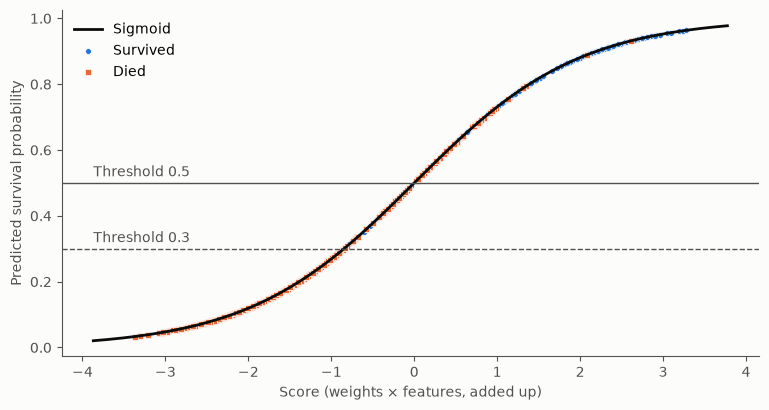

In [2]:
model = LogisticRegression().fit(X, y)
scores = model.decision_function(X)
line = np.linspace(scores.min() - 0.5, scores.max() + 0.5, 300)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(line, 1 / (1 + np.exp(-line)), color=INK, linewidth=2, label="Sigmoid")
points = np.c_[scores, model.predict_proba(X)[:, 1]]
scatter(ax, points, y.to_numpy(), size=18)
ax.axhline(0.5, color=MUTED, linewidth=1)
ax.axhline(0.3, color=MUTED, linewidth=1, linestyle="--")
ax.text(line.min(), 0.51, "Threshold 0.5", color=MUTED, va="bottom")
ax.text(line.min(), 0.31, "Threshold 0.3", color=MUTED, va="bottom")
ax.set_xlabel("Score (weights × features, added up)")
ax.set_ylabel("Predicted survival probability")
ax.legend(loc="upper left", frameon=False)
plt.show()

## 2. Clean example data

Two made-up, well-separated groups, because the idea is easiest to see here.

- **Left:** the colour fades near the line. Logistic regression knows which passengers are close calls.
- **Right:** only the circled points set the street (dashed lines mark its edges). Moving any other point changes nothing.

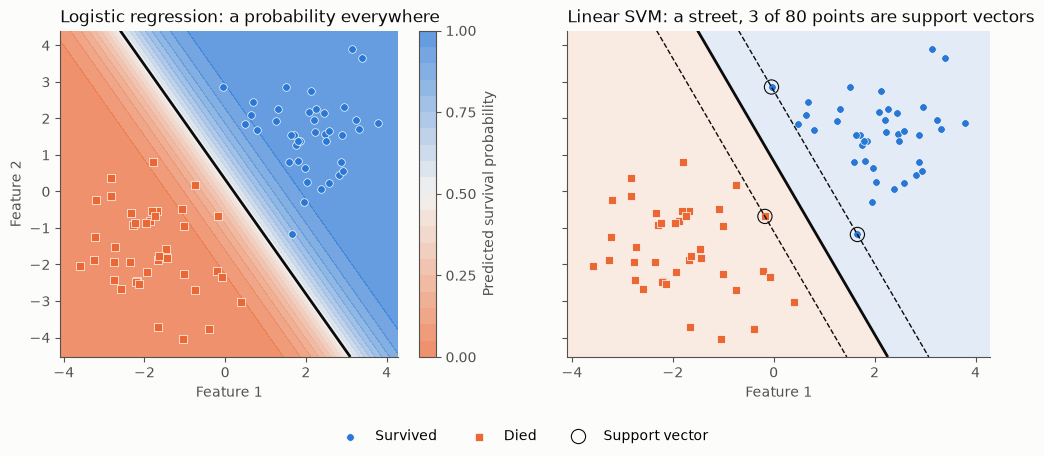

In [3]:
X_blobs, y_blobs = make_blobs(n_samples=80, centers=[[-2, -1.5], [2, 1.5]], cluster_std=1.1, random_state=1)
compare(X_blobs, y_blobs, "Feature 1", "Feature 2", size=30)

## 3. Real Titanic data: `Age` and `Fare`

The same two pictures on the training set, using only two features. The classes overlap heavily, so the SVM can no longer keep a clean street: many passengers end up inside it or on the wrong side, and they all become support vectors. The vertical stripe near `Age` 0 is the passengers whose missing age was filled with the median. The y-axis is cut off at the 97th percentile for readability, but the models are fitted on all 640 rows.

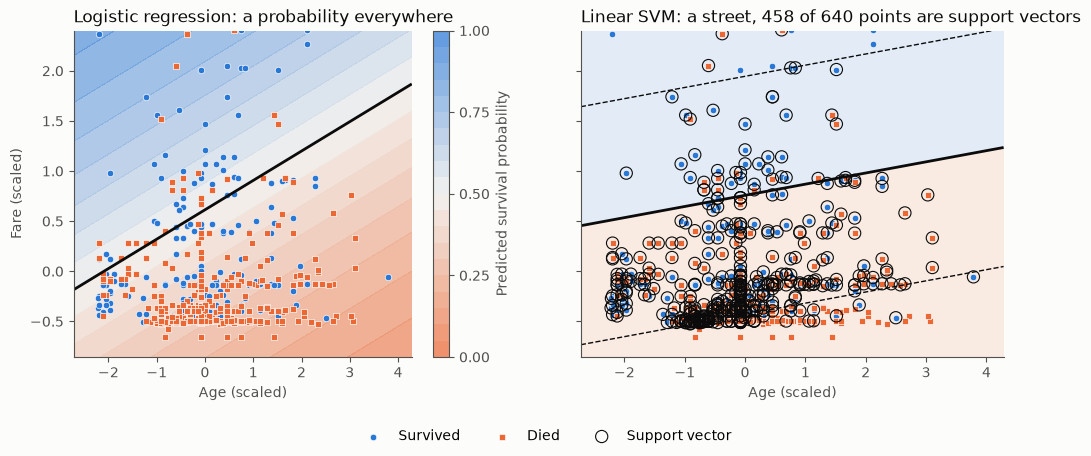

In [4]:
X_real = train[["Age", "Fare"]].to_numpy()
compare(X_real, y.to_numpy(), "Age (scaled)", "Fare (scaled)", ylim=(X_real[:, 1].min() - 0.2, np.percentile(X_real[:, 1], 97)))